# Test accuracy on duplicated videos

| Run | Model | Split |
|-----|-------|-------|
| `MViTv2_S_16x4_e_5mzfq88e_chained_s42` (thesis job 4's final model) | MViTv2_S_16x4_e | asl2000 |

WLASL-2000 contains identical videos filed under several glosses, some of them split across
train and test. This notebook asks how the model does on test videos that have an identical copy
elsewhere in the dataset, split by where the copy is and whether it carries the same gloss, and
how per-gloss F1, precision and recall vary with each kind of copy.

What the copies are and where they fall is in
[duplicate_clips.ipynb](../dataset_analysis/duplicate_clips.ipynb), which also defines the kinds
(repeat, leak, conflict within / across sets). Copies are byte-identical files, flagged by
[`duplicates.py`](../dataset_analysis/duplicates.py); before 3 Nov 2026 this notebook read them
from `find_duplicates.py`'s report (since merged into it), with the same 900 copied clips. Top-k predictions are
the stash from [all_misspredictions.ipynb](./all_misspredictions.ipynb). Dataset fields and
gotchas: [WLASL_info.md](../../info/WLASL_info.md).

In [1]:
from typing import Literal, NamedTuple, TypeAlias

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from pydantic import TypeAdapter
from scipy.stats import kendalltau, mannwhitneyu
from sklearn.metrics import f1_score, precision_recall_fscore_support

from src.configs import get_class_list
from src.results import (
    format_exp_label,
    get_asset_path,
    get_out_stub,
    get_stash_path,
    load_json,
)
from src.results.dataset_analysis.duplicates import (
    GLOSS_MEASURES,
    SETS,
    TwinRelation,
    gloss_measures,
    load_flagged,
    twin_pairs,
    twin_set_column,
)
from src.run_types import AVAIL_SETS, AVAIL_SPLITS, InstanceTopK
from src.visualise2 import (
    plot_correlation_bars,
    plot_grouped_bar_chart,
    save_fig,
    set_thesis_style,
)

set_thesis_style()

## Setup

In [2]:
split_name: AVAIL_SPLITS = 'asl2000'
set_name: AVAIL_SETS = 'test' # the set the predictions were stashed for
model_name = 'MViTv2_S_16x4_e' # the S3D comparison: 'S3D'
exp_no = 'MViTv2_S_16x4_e_5mzfq88e_chained_s42' # the S3D comparison: 'S3D_cs9lwmiy_s42'
checkpoint_num = None
top_n = 5 # the second accuracy reported, alongside top-1
project_name = 'error_analysis'

stub = get_out_stub(split_name, model_name, format_exp_label(exp_no), checkpoint_num)
classes = get_class_list()
predictions = TypeAdapter(list[InstanceTopK]).validate_python(
    load_json(get_stash_path(stub, base_name='instance_topk'))
)
flagged = load_flagged('asl2000')  # twins over all of WLASL-2000
assert {p.video_id for p in predictions} == set(flagged.loc[flagged['set'] == set_name, 'video_id'])
print(f'{len(predictions)} {set_name} predictions; {len(flagged)} instances, {flagged["md5"].nunique()} distinct clips')

2879 test predictions; 21095 instances, 20010 distinct clips


## Where each test video's copies are

Copies are flagged on the plain `asl2000` split, which this run was trained on, so every
instance counts.

In [3]:
class Copy(NamedTuple):
    video_id: str
    gloss: str
    set: str


copies_of: dict[str, list[Copy]] = {}
for pair in twin_pairs(flagged).itertuples():
    copies_of.setdefault(str(pair.video_id), []).append(
        Copy(str(pair.video_id_twin), str(pair.gloss_twin), str(pair.set_twin))
    )

CopyKind: TypeAlias = Literal[
    'no copy',
    'train copy, other gloss',
    'train copy, same gloss',
    'train copy, same and other gloss',
    'val copy only',
    'test copy only',
]


def copy_kind(gloss: str, copies: list[Copy]) -> CopyKind:
    """Classify a video by its copies: training copies take precedence over val, then test."""
    train_glosses = {m.gloss for m in copies if m.set == 'train'}
    if train_glosses:
        same, other = gloss in train_glosses, bool(train_glosses - {gloss})
        if same and other:
            return 'train copy, same and other gloss'
        return 'train copy, same gloss' if same else 'train copy, other gloss'
    if any(m.set == 'val' for m in copies):
        return 'val copy only'
    return 'test copy only' if copies else 'no copy'


def other_glosses_in(copies: list[Copy], gloss: str, set_name: str) -> set[str]:
    """The glosses other than `gloss` that `copies` carry in `set_name`."""
    return {m.gloss for m in copies if m.set == set_name} - {gloss}


rows: list[dict[str, object]] = []
for pred in predictions:
    gloss = classes[pred.target]
    copies = sorted(copies_of.get(pred.video_id, []))
    train_other = other_glosses_in(copies, gloss, 'train')
    top = [classes[i] for i in pred.topk_idxs]
    rows.append({
        'video_id': pred.video_id,
        'gloss': gloss,
        'kind': copy_kind(gloss, copies),
        'predicted': top[0],
        'confidence': pred.topk_probs[0],
        'top1': top[0] == gloss,
        f'top{top_n}': gloss in top[:top_n],
        'pred_is_train_copy_gloss': top[0] in train_other,
        f'train_copy_gloss_in_top{top_n}': bool(train_other & set(top[:top_n])),
        **{f'pred_is_{s}_copy_gloss': top[0] in other_glosses_in(copies, gloss, s) for s in SETS},
        'copies': ', '.join(f'{m.video_id} {m.gloss}/{m.set}' for m in copies),
    })
twin_cols = [twin_set_column(r, s) for r in ('other_gloss', 'same_gloss') for s in SETS]
df = pd.DataFrame(rows).merge(flagged[['video_id', 'has_twin', 'twin_other_gloss', *twin_cols]], on='video_id')
assert df['video_id'].is_unique and len(df) == len(predictions)

## Accuracy by kind of copy (%)

In [4]:
kind_order = list(CopyKind.__args__)  # pyright: ignore[reportAttributeAccessIssue]
summary = (
    df.groupby('kind')
    .agg(
        n=('video_id', 'size'),
        top1=('top1', 'mean'),
        **{f'top{top_n}': (f'top{top_n}', 'mean')},
        pred_is_train_copy_gloss=('pred_is_train_copy_gloss', 'mean'),
        **{f'train_copy_gloss_in_top{top_n}': (f'train_copy_gloss_in_top{top_n}', 'mean')},
    )
    .reindex([k for k in kind_order if k in set(df['kind'])])
)
pct_cols = [c for c in summary.columns if c != 'n']
summary[pct_cols] = (summary[pct_cols] * 100).round(2)
summary

,n,top1,top5,pred_is_train_copy_gloss,train_copy_gloss_in_top5
kind,,,,,
no copy,2689,55.93,85.20,0.0,0.0
"train copy, other gloss",147,0.00,91.84,100.0,100.0
"train copy, same gloss",8,100.00,100.00,0.0,0.0
"train copy, same and other gloss",1,100.00,100.00,0.0,100.0
val copy only,28,42.86,92.86,0.0,0.0
test copy only,6,33.33,100.00,0.0,0.0


### By where the copy is

The same test videos, by where a copy is and whether it has another gloss (rows overlap: a video
with copies in train and val is in both). `pred is the copy's gloss` is the share predicted as
one of those copies' other glosses.

In [5]:
def place_row(relation: TwinRelation, place: str) -> dict[str, float]:
    sub = df[df[twin_set_column(relation, place)]]
    row = {'n': len(sub), 'top1': sub['top1'].mean(), f'top{top_n}': sub[f'top{top_n}'].mean()}
    if relation == 'other_gloss':
        row['pred is the copy\'s gloss'] = sub[f'pred_is_{place}_copy_gloss'].mean()
    return row


by_place = pd.DataFrame(
    {
        (relation.replace('_', ' '), f'copy in {place}'): place_row(relation, place)
        for relation in ('other_gloss', 'same_gloss')
        for place in SETS
    }
).T
by_place[by_place.columns.drop('n')] *= 100
by_place.astype({'n': int}).round(2)

n    top1    top5  pred is the copy's gloss
other gloss copy in train  148    0.68   91.89                     99.32
            copy in val     41   24.39   87.80                     24.39
            copy in test    14   21.43  100.00                     21.43
same gloss  copy in train    9  100.00  100.00                       NaN
            copy in val      5   60.00  100.00                       NaN
            copy in test     0     NaN     NaN                       NaN

## Overall top-1 with and without the duplicated test videos (%)

In [6]:
def top1_pct(mask: 'pd.Series[bool]') -> float:
    return round(float(df.loc[mask, 'top1'].mean()) * 100, 2)


every = pd.Series(True, index=df.index)
conflicting = df['kind'].isin(['train copy, other gloss'])
any_conflict = df['twin_other_gloss']
any_copy = df['kind'] != 'no copy'
overall = pd.DataFrame(
    {
        'n': [int(every.sum()), int((~conflicting).sum()), int((~any_conflict).sum()), int((~any_copy).sum())],
        'top1': [top1_pct(every), top1_pct(~conflicting), top1_pct(~any_conflict), top1_pct(~any_copy)],
    },
    index=[
        f'all {set_name} videos (as reported)',
        'without videos whose only training copies have another gloss',
        'without videos with a copy under another gloss (any set)',
        'without any duplicated video',
    ],
)
overall

,n,top1
all test videos (as reported),2879,53.04
without videos whose only training copies have another gloss,2732,55.89
without videos with a copy under another gloss (any set),2699,56.09
without any duplicated video,2689,55.93


## Test videos whose training copy has another gloss

The model's prediction against the copy's gloss, for every such video.

In [7]:
conflicts = df.loc[conflicting, ['video_id', 'gloss', 'predicted', 'confidence', 'copies']]
print(f'{len(conflicts)} videos; prediction is a training copy\'s gloss for '
      f'{int(df.loc[conflicting, "pred_is_train_copy_gloss"].sum())}')
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(conflicts.sort_values('gloss').reset_index(drop=True))

147 videos; prediction is a training copy's gloss for 147


,video_id,gloss,predicted,confidence,copies
0,02128,a lot,much,0.993501,37198 much/train
1,02048,allow,let,0.991111,32916 let/train
2,02049,allow,permit,0.993494,42142 permit/train
3,02544,angel,fairy,0.997131,20838 fairy/train
4,02545,angel,fairy,0.995293,20839 fairy/train
5,02701,another,other,0.588072,"18858 else/train, 40317 other/train"
6,02715,answer,reply,0.505976,"47345 reply/train, 47362 report/train"
7,03125,approve,take,0.984468,"00600 accept/val, 01159 adopt/val, 56700 take/train"
8,03278,argue,quarrel,0.962436,45656 quarrel/train
9,04429,awful,terrible,0.988015,57489 terrible/train


## Identical test videos with different glosses

Pairs like these can't both be right: the input is the same, the targets differ.

In [8]:
test_conflicts = df[df[twin_set_column('other_gloss', 'test')]]
print(f'{len(test_conflicts)} test videos have an identical test video with another gloss')
test_conflicts[['video_id', 'gloss', 'predicted', 'top1', 'copies']].sort_values('video_id')

14 test videos have an identical test video with another gloss


,video_id,gloss,predicted,top1,copies
1351,03425,arrest,pass,False,09468 catch/test
16,05741,before,past,False,"01556 ago/train, 32253 last/test, 41452 past/t..."
598,09468,catch,pass,False,03425 arrest/test
2225,12217,complete,end,False,19114 end/test
1090,14839,dead,death,False,"14955 death/train, 16164 die/test"
1968,16164,die,death,False,"14839 dead/test, 14955 death/train"
1116,19114,end,end,True,12217 complete/test
178,32253,last,past,False,"01556 ago/train, 05741 before/test, 41452 past..."
2076,46333,realize,reason,False,46433 reason/test
1231,46374,really,real,False,"46317 real/train, 56035 sure/test, 59795 true/..."


## Per-class F-1 by duplicate involvement

Each test gloss's F-1, comparing glosses that share an identical video with another gloss (in any
set) against the rest. Training signer counts are over all of plain `asl2000`. For this run, 849
glosses have mean F-1 0.27 against 0.59 for the other 1,151, and 0.31 against 0.59 without any
test video from a cross-gloss group.

In [9]:
def per_class_f1(preds: list[InstanceTopK]) -> dict[str, float]:
    """Top-1 F-1 of every gloss with a test video in `preds`."""
    targets = [p.target for p in preds]
    labels = sorted(set(targets))
    scores = f1_score(targets, [p.topk_idxs[0] for p in preds], labels=labels, average=None, zero_division=0)
    return {classes[label]: float(score) for label, score in zip(labels, scores, strict=True)}


trained_on = flagged[flagged['set'] == 'train']
train_signers = trained_on.groupby('gloss')['signer_id'].nunique()
test_flagged = flagged[flagged['set'] == 'test']
cross = set(flagged.loc[flagged['twin_other_gloss'], 'gloss'])  # shares a video with another gloss, any set
other_in_train = flagged[twin_set_column('other_gloss', 'train')]
cross_train = set(flagged.loc[other_in_train, 'gloss'])  # has a video whose training copy carries another gloss
conflict_test = set(  # has a test video whose only training copies carry another gloss
    test_flagged.loc[
        test_flagged[twin_set_column('other_gloss', 'train')] & ~test_flagged[twin_set_column('same_gloss', 'train')],
        'gloss',
    ]
)

f1_df = pd.DataFrame(per_class_f1(predictions).items(), columns=['gloss', 'f1'])
f1_df['cross'] = f1_df['gloss'].isin(cross)
f1_df['signers'] = f1_df['gloss'].map(train_signers).fillna(0).astype(int)
print(f"{len(f1_df)} test glosses, mean F-1 {f1_df['f1'].mean():.3f}")

2000 test glosses, mean F-1 0.453


In [10]:
def compare(mask: 'pd.Series[bool]') -> dict[str, float]:
    """F-1 of the glosses in `mask` against the rest, with a Mann-Whitney U test."""
    a, b = f1_df.loc[mask, 'f1'], f1_df.loc[~mask, 'f1']
    return {
        'n': len(a), 'mean': a.mean(), 'median': a.median(), 'zero F-1 (%)': (a == 0).mean() * 100,
        'rest n': len(b), 'rest mean': b.mean(), 'rest median': b.median(),
        'rest zero F-1 (%)': (b == 0).mean() * 100, 'MWU p': float(mannwhitneyu(a, b).pvalue),
    }


comparison = pd.DataFrame(
    {
        'shares a video with another gloss (any set)': compare(f1_df['cross']),
        "a training copy carries another gloss": compare(f1_df['gloss'].isin(cross_train)),
        'a test video whose only training copies carry another gloss': compare(
            f1_df['gloss'].isin(conflict_test)
        ),
    }
).T
comparison['MWU p'] = comparison['MWU p'].map('{:.2g}'.format)
comparison.round(3)

,n,mean,median,zero F-1 (%),rest n,rest mean,rest median,rest zero F-1 (%),MWU p
shares a video with another gloss (any set),849.0,0.273,0.0,59.128,1151.0,0.585,0.667,28.323,3.6e-63
a training copy carries another gloss,762.0,0.274,0.0,59.318,1238.0,0.563,0.667,30.372,8.9e-53
a test video whose only training copies carry another gloss,139.0,0.161,0.0,68.345,1861.0,0.475,0.500,39.387,2.3e-18


### Within training-signer-count bins

The gap isn't explained by cross-gloss glosses having fewer training signers: it holds in every bin
that has cross-gloss glosses.

In [11]:
f1_df['signer bin'] = pd.cut(f1_df['signers'], [0, 5, 8, 11, 14, 100])
f1_df.groupby(['signer bin', 'cross'], observed=True)['f1'].agg(['count', 'mean']).round(3).unstack()

count          mean       
cross       False  True   False  True 
signer bin                            
(0, 5]      422.0  355.0  0.496  0.178
(5, 8]      520.0  381.0  0.605  0.297
(8, 11]     170.0  101.0  0.703  0.498
(11, 14]     37.0   12.0  0.785  0.445
(14, 100]     2.0    NaN  0.619    NaN

### Without the cross-gloss test videos

F-1 recomputed after dropping every test video that belongs to a cross-gloss group, so the
remaining gap isn't just those videos being mislabelled.

In [12]:
cross_videos = set(flagged.loc[flagged['twin_other_gloss'], 'video_id'])
kept = [p for p in predictions if p.video_id not in cross_videos]
f1_kept = f1_df[['gloss', 'cross']].assign(f1=f1_df['gloss'].map(per_class_f1(kept))).dropna()
print(f'{len(kept)} of {len(predictions)} test videos kept')
f1_kept.groupby('cross')['f1'].agg(['count', 'mean']).round(3)

2699 of 2879 test videos kept


,count,mean
cross,,
False,1151,0.586
True,784,0.312


### Under-achievers

Glosses with F-1 at most 0.2 despite at least 13 training signers, with the glosses they share a
video with.

In [13]:
glosses_of_clip = flagged.groupby('md5')['gloss'].agg(set)
shares_with = {
    gloss: ', '.join(sorted(set().union(*glosses_of_clip[clips]) - {gloss}))
    for gloss, clips in flagged[flagged['twin_other_gloss']].groupby('gloss')['md5']
}
under = f1_df[(f1_df['f1'] <= 0.2) & (f1_df['signers'] >= 13)].copy()
under['shares a video with'] = under['gloss'].map(shares_with).fillna('')
under[['gloss', 'f1', 'signers', 'shares a video with']].sort_values('gloss').reset_index(drop=True)

,gloss,f1,signers,shares a video with
0,before,0.0,13,"ago, last, past"
1,eat,0.0,13,"food, snack"
2,thin,0.0,13,skinny


## Per-gloss measures by kind of copy

The comparisons above lump every kind of copy together. Here each gloss gets one measure per kind,
by what that kind does to the model:

- a **train-train conflict** gives contradictory training targets;
- a **test-train conflict** is a test clip the model was taught as another gloss, which costs this
  gloss recall *and* the other gloss precision (it is a false positive there), hence
  `lends_to_test`, counted on the other gloss;
- a **test-val conflict** only reaches the model through model selection;
- a **test-test conflict** is one input with two targets;
- a **leak** is a test clip the model was taught under its own gloss.

Each measure, apart from `lends_to_test` (a count), is a **share**: a fraction from 0 to 1 of the
gloss's instances in the named set (all sets for `_any`), not a yes/no. The twin's set is part of
the condition and the conditions overlap: a test instance with twins in train and in test counts
towards both `conflict_test_train` and `conflict_test_test`. A gloss is **flagged** for a measure
when it is above 0. Per-gloss precision, recall and F-1 are top-1, over the test set.

In [14]:
with pd.option_context('display.max_colwidth', None):
    display(pd.Series(GLOSS_MEASURES, name='what it measures, per gloss').to_frame())

precision, recall, f1, _ = precision_recall_fscore_support(
    [p.target for p in predictions], [p.topk_idxs[0] for p in predictions],
    labels=list(range(len(classes))), average=None, zero_division=0,
)
per_gloss = gloss_measures(flagged).join(
    pd.DataFrame({'precision': precision, 'recall': recall, 'f1': f1}, index=pd.Index(classes, name='gloss'))
)
per_gloss['train_signers'] = train_signers.reindex(per_gloss.index, fill_value=0)
per_gloss['train_instances'] = trained_on.groupby('gloss').size().reindex(per_gloss.index, fill_value=0)
assert len(per_gloss) == 2000
assert (per_gloss['f1'] - f1_df.set_index('gloss')['f1']).abs().max() < 1e-12
per_gloss.sort_values('conflict_any', ascending=False).head(10).round(3)

,"what it measures, per gloss"
twin_any,share of all its instances with a twin of any kind
conflict_any,"share of all its instances with a twin under another gloss, in any set"
conflict_train_train,share of its train instances with a twin under another gloss in train: contradictory training targets
conflict_test_train,share of its test instances with a twin under another gloss in train: the model has been taught that clip as the other gloss
conflict_test_val,share of its test instances with a twin under another gloss in val
conflict_test_test,"share of its test instances with a twin under another gloss in test: one input, two targets, so at most one is right"
leak_test,share of its test instances with a twin under the same gloss in train or val
lends_to_test,"number of other glosses' test instances whose twin in train has this gloss: each is a likely false positive for it (a count, not a share)"


,twin_any,conflict_any,conflict_train_train,conflict_test_train,conflict_test_val,conflict_test_test,leak_test,lends_to_test,precision,recall,f1,train_signers,train_instances
gloss,,,,,,,,,,,,,
put off,0.857,0.857,0.800,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,4,5
freeway,0.714,0.714,0.600,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,4,5
trip,0.714,0.714,0.400,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,4,5
precipitation,0.714,0.714,0.400,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,4,5
soul,0.714,0.714,0.800,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3,5
sprint,0.714,0.714,0.800,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4,5
host,0.714,0.714,0.800,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,5,5
her,0.636,0.636,0.714,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5,7
physician,0.625,0.625,0.600,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,5,5


### Glosses flagged for each kind, against glosses with no copy at all

Each row is the glosses flagged for one measure; the baseline is the glosses with no copy of any
kind, rather than "the rest", which still holds glosses with other kinds of copy. The MWU p
compares F-1 with that baseline. The two halves of a test-train conflict are side by side:
`conflict_test_train` (the gloss whose test clip was taught as another) and `lends_to_test` (the
gloss it was taught as).

The kinds overlap: a gloss is in every row it is flagged for, so a row's scores mix in the effect
of the gloss's other kinds. How much each pair of rows shares is in the table below the chart.

,glosses,F-1,precision,recall,zero F-1 (%),median train signers,MWU p
no copy (baseline),1120,0.581,0.580,0.633,28.750,6.0,nan
any label conflict,849,0.273,0.261,0.327,59.128,6.0,3.9e-61
conflict train train,663,0.270,0.256,0.325,60.030,6.0,4.2e-53
conflict test train,140,0.167,0.194,0.158,67.857,7.0,2.1e-29
lends to test,163,0.188,0.153,0.267,67.485,6.0,1.6e-29
conflict test val,40,0.235,0.238,0.267,57.500,7.5,7e-08
conflict test test,14,0.186,0.167,0.238,64.286,7.0,0.00029
leak test,14,0.683,0.679,0.762,14.286,7.0,0.35


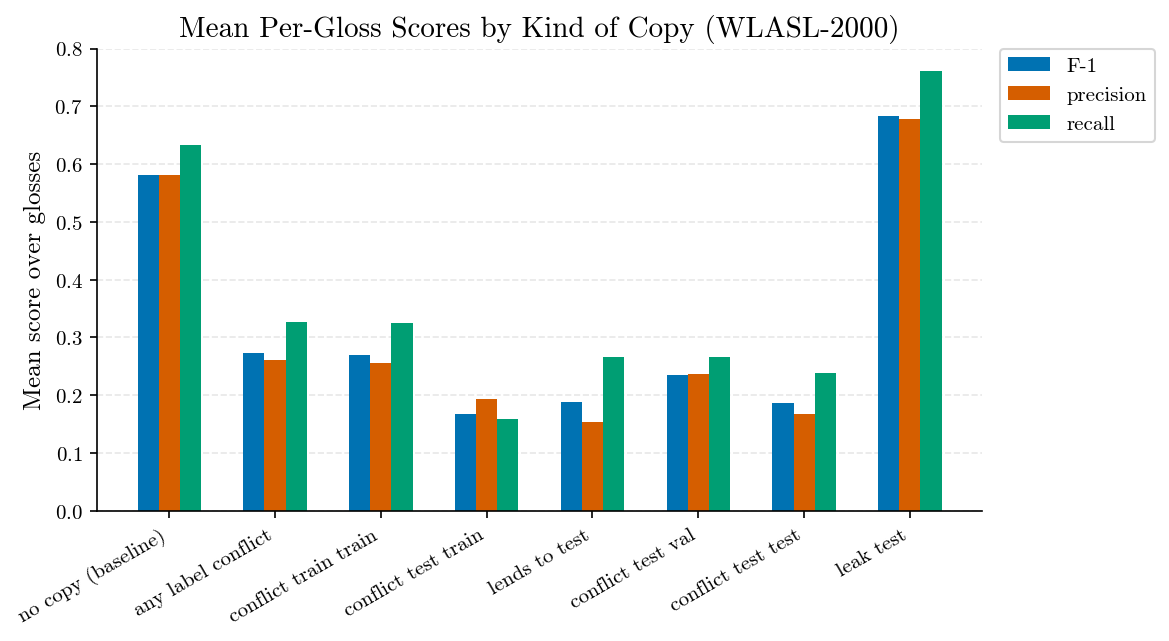

In [15]:
clean = per_gloss['twin_any'] == 0
def measure_label(measure: str) -> str:
    """A `GLOSS_MEASURES` key as shown in tables and charts."""
    return measure.replace('_', ' ')


kind_measures = [
    'conflict_train_train', 'conflict_test_train', 'lends_to_test', 'conflict_test_val', 'conflict_test_test', 'leak_test',
]
assert set(kind_measures) == set(GLOSS_MEASURES) - {'twin_any', 'conflict_any'}
flags = {'no copy (baseline)': clean, 'any label conflict': per_gloss['conflict_any'] > 0} | {
    measure_label(m): per_gloss[m] > 0 for m in kind_measures
}


def against_clean(mask: 'pd.Series[bool]') -> dict[str, float]:
    a = per_gloss[mask]
    return {
        'glosses': len(a), 'F-1': a['f1'].mean(), 'precision': a['precision'].mean(),
        'recall': a['recall'].mean(), 'zero F-1 (%)': (a['f1'] == 0).mean() * 100,
        'median train signers': a['train_signers'].median(),
        'MWU p': float(mannwhitneyu(a['f1'], per_gloss.loc[clean, 'f1']).pvalue),
    }


by_kind = pd.DataFrame({name: against_clean(mask) for name, mask in flags.items()}).T
by_kind.loc['no copy (baseline)', 'MWU p'] = float('nan')
display(by_kind.round(3).astype({'glosses': int}).assign(**{'MWU p': by_kind['MWU p'].map('{:.2g}'.format)}))

fig, ax = plot_grouped_bar_chart(
    list(by_kind.index),
    {m: by_kind[m].to_numpy() for m in ('F-1', 'precision', 'recall')},
    title='Mean Per-Gloss Scores by Kind of Copy (WLASL-2000)',
    ylabel='Mean score over glosses',
    rotation=30,
    show_values=False,
)
save_fig(fig, get_asset_path('dup_kind_scores', stub, project_name))
plt.show()

### How much the kinds overlap

Glosses flagged for both the row's and the column's kind (the diagonal is each kind's total).
Read a row of the chart above with its row here: e.g. the test-val glosses also hold test-train
and train-train ones, so the test-val bar is not the effect of test-val conflicts alone.

Per test clip there is no overlap, since each clip is counted once. The test clips whose
conflicting copies are all in val, which the model never trains on, isolate the test-val case:
their copy can't have taught the model a wrong label. Their gloss can still conflict elsewhere,
so the second table splits them by whether the same two glosses also share a clip in train
(another clip the model *was* taught under both), and gives how many errors are the val copy's
gloss.

In [16]:
kinds = [k for k in flags if k != 'no copy (baseline)']
overlap = pd.DataFrame({b: {a: int((flags[a] & flags[b]).sum()) for a in kinds} for b in kinds})
display(overlap)

train_copy = df[[twin_set_column(r, 'train') for r in ('other_gloss', 'same_gloss')]].any(axis=1)
val_conflict_only = df[twin_set_column('other_gloss', 'val')] & ~train_copy
val_only = df[val_conflict_only].copy()
display(
    pd.DataFrame(
        {
            name: {'n': int(mask.sum()), 'top1': df.loc[mask, 'top1'].mean() * 100}
            for name, mask in {
                'no copy': df['kind'] == 'no copy',
                'copy under another gloss in val, none in train': val_conflict_only,
                'copy under another gloss in train only': df['kind'] == 'train copy, other gloss',
            }.items()
        }
    ).T.astype({'n': int}).round(2)
)

pairs = twin_pairs(flagged)
train_train = pairs[(pairs['set'] == 'train') & (pairs['set_twin'] == 'train') & ~pairs['same_gloss']]
taught_together = set(zip(train_train['gloss'], train_train['gloss_twin']))
val_glosses = val_only['video_id'].map(lambda v: other_glosses_in(copies_of[v], '', 'val'))
val_only['pair shares a train clip'] = [
    any((g, o) in taught_together for o in others - {g}) for g, others in zip(val_only['gloss'], val_glosses)
]
val_only['pred is the val copy\'s gloss'] = [
    p in others - {g} for p, g, others in zip(val_only['predicted'], val_only['gloss'], val_glosses)
]
val_only.groupby('pair shares a train clip').agg(
    n=('top1', 'size'), correct=('top1', 'sum'), errors_to_val_gloss=("pred is the val copy's gloss", 'sum')
)

,any label conflict,conflict train train,conflict test train,lends to test,conflict test val,conflict test test,leak test
any label conflict,849,663,140,163,40,14,6
conflict train train,663,663,97,125,28,8,4
conflict test train,140,97,140,21,20,7,3
lends to test,163,125,21,163,4,2,1
conflict test val,40,28,20,4,40,3,2
conflict test test,14,8,7,2,3,14,0
leak test,6,4,3,1,2,0,14


,n,top1
no copy,2689,55.93
"copy under another gloss in val, none in train",25,36.00
copy under another gloss in train only,147,0.00


,n,correct,errors_to_val_gloss
pair shares a train clip,,,
False,9,3,4
True,16,6,6


#### Against clips from the same signers

Label conflicts come mostly from a few signers on dictionary sites (signer 11 on `signingsavvy` is
36% of conflicting instances), so the 25 val-only clips are compared with the no-copy test clips of
the same (signer, source) pairs, weighted to the 25's mix of pairs. This is the top-1 the 25 would
be expected to reach if their copy made no difference.

In [17]:
recorded_by = ['signer_id', 'source']
with_signer = df.merge(flagged[['video_id', *recorded_by]], on='video_id')
val_only_mix = with_signer[val_conflict_only.to_numpy()].groupby(recorded_by)['top1'].agg(['size', 'sum'])
no_copy_top1 = with_signer[with_signer['kind'] == 'no copy'].groupby(recorded_by)['top1'].agg(['size', 'mean'])
matched = val_only_mix.join(no_copy_top1, rsuffix=' no copy')
assert matched['mean'].notna().all()
expected = (matched['mean'] * matched['size']).sum() / matched['size'].sum()
print(
    f"val-only top-1 {val_only_mix['sum'].sum() / val_only_mix['size'].sum():.1%}; "
    f"no-copy clips of the same signers and sources, weighted to match: {expected:.1%}"
)
matched.rename(columns={'size': 'val-only clips', 'sum': 'val-only correct', 'size no copy': 'no-copy clips', 'mean': 'no-copy top1'}).round(3)

val-only top-1 36.0%; no-copy clips of the same signers and sources, weighted to match: 64.3%


,,val-only clips,val-only correct,no-copy clips,no-copy top1
signer_id,source,,,,
4,signschool,1,0,87,0.575
10,signingsavvy,4,2,47,0.617
11,signingsavvy,11,4,146,0.651
13,asldeafined,4,0,108,0.667
21,asldeafined,2,2,38,0.711
32,signschool,1,1,33,0.485
59,asldeafined,1,0,28,0.643
60,signschool,1,0,9,0.667


### Within training-signer-count bins, by kind

Mean F-1 (and number of glosses) per signer bin, for the baseline and the main kinds, so a kind
isn't just standing in for fewer training signers.

In [18]:
main_kinds = ['no copy (baseline)', 'any label conflict'] + [
    measure_label(m) for m in ('conflict_train_train', 'conflict_test_train', 'lends_to_test')
]
signer_bins = pd.cut(per_gloss['train_signers'], [0, 5, 8, 11, 100])
pd.concat(
    {
        stat: pd.DataFrame({k: per_gloss.loc[flags[k], 'f1'].groupby(signer_bins[flags[k]], observed=True).agg(stat) for k in main_kinds})
        for stat in ('count', 'mean')
    },
    axis=1,
).round(3)

count                                          \
              no copy (baseline) any label conflict conflict train train   
train_signers                                                              
(0, 5]                       416                355                  291   
(5, 8]                       503                381                  282   
(8, 11]                      164                101                   78   
(11, 100]                     37                 12                   12   

                                                              mean  \
              conflict test train lends to test no copy (baseline)   
train_signers                                                        
(0, 5]                         23            81              0.495   
(5, 8]                         89            65              0.599   
(8, 11]                        27            13              0.703   
(11, 100]                       1             4              0.773   

                                                                           \
              any label conflict conflict train train conflict test train   
train_signers                                                               
(0, 5]                     0.178                0.172               0.000   
(5, 8]                     0.297                0.299               0.158   
(8, 11]                    0.498                0.505               0.345   
(11, 100]                  0.445                0.445               0.000   

                             
              lends to test  
train_signers                
(0, 5]                0.075  
(5, 8]                0.278  
(8, 11]               0.461  
(11, 100]             0.125

### Kendall's τ of each measure with per-gloss scores

Rank correlation of each measure with F-1, precision and recall, with training signers and
instances as references (F-1 rises with both, see
[correlation_f1.ipynb](./correlation_f1.ipynb)). Many glosses have a share of 0, and τ accounts for
the ties. The table has every measure; the chart (thesis, from 2026-11-05) shows F-1 only, since
precision and recall are within about 0.05 of it, leaves out `twin_any` (close to `conflict_any`)
and the rare `conflict_test_val`/`conflict_test_test`, and groups the reference measures below the
duplicate ones. Its second bar is a control: `conflict_any` against F-1 recomputed without the
cross-gloss test videos ([above](#Without-the-cross-gloss-test-videos)), so the τ isn't only those
clips being scored wrong by construction. Hatched bars have p ≥ 0.05.


F-1         precision          recall          \
                         tau       p       tau       p     tau       p   
twin_any             -0.3162  0.0000   -0.3187  0.0000 -0.2958  0.0000   
conflict_any         -0.3360  0.0000   -0.3400  0.0000 -0.3140  0.0000   
conflict_train_train -0.2873  0.0000   -0.2942  0.0000 -0.2676  0.0000   
conflict_test_train  -0.1766  0.0000   -0.1519  0.0000 -0.1991  0.0000   
conflict_test_val    -0.0706  0.0005   -0.0629  0.0022 -0.0704  0.0009   
conflict_test_test   -0.0503  0.0133   -0.0497  0.0157 -0.0461  0.0298   
leak_test             0.0429  0.0346    0.0424  0.0393  0.0442  0.0370   
lends_to_test        -0.1741  0.0000   -0.1856  0.0000 -0.1468  0.0000   
train_signers         0.1850  0.0000    0.2370  0.0000  0.1739  0.0000   
train_instances       0.1687  0.0000    0.2295  0.0000  0.1536  0.0000   

                     glosses > 0  
                                  
twin_any                     880  
conflict_any                 849  
conflict_train_train         663  
conflict_test_train          140  
conflict_test_val             40  
conflict_test_test            14  
leak_test                     14  
lends_to_test                163  
train_signers               2000  
train_instances             2000

Control over 1935 glosses: tau -0.2885, p 4e-53


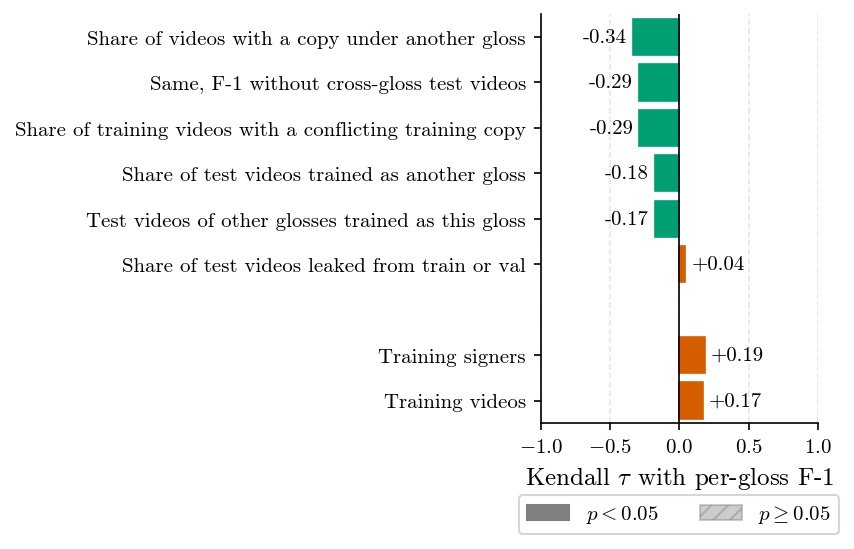

In [19]:
tau_measures = [m for m in GLOSS_MEASURES] + ['train_signers', 'train_instances']
scores = {'F-1': 'f1', 'precision': 'precision', 'recall': 'recall'}
taus = {name: [kendalltau(per_gloss[m], per_gloss[col]) for m in tau_measures] for name, col in scores.items()}
tau_table = pd.concat(
    {
        name: pd.DataFrame({'tau': [t.statistic for t in ts], 'p': [t.pvalue for t in ts]}, index=tau_measures)
        for name, ts in taus.items()
    },
    axis=1,
).assign(**{'glosses > 0': [int((per_gloss[m] > 0).sum()) for m in tau_measures]})
display(tau_table.round(4))

# The control: F-1 over the glosses that keep a test video once the cross-gloss ones are dropped.
without_cross = per_gloss[['conflict_any']].join(f1_kept.set_index('gloss')['f1'], how='inner')
control = kendalltau(without_cross['conflict_any'], without_cross['f1'])
print(f'Control over {len(without_cross)} glosses: tau {control.statistic:.4f}, p {control.pvalue:.2g}')

chart_labels = {  # plain English for the thesis
    'conflict_any': 'Share of videos with a copy under another gloss',
    'control': 'Same, F-1 without cross-gloss test videos',
    'conflict_train_train': 'Share of training videos with a conflicting training copy',
    'conflict_test_train': 'Share of test videos trained as another gloss',
    'lends_to_test': 'Test videos of other glosses trained as this gloss',
    'leak_test': 'Share of test videos leaked from train or val',
    'train_signers': 'Training signers',
    'train_instances': 'Training videos',
}
chart_tau = tau_table[('F-1', 'tau')].to_dict() | {'control': control.statistic}
chart_p = tau_table[('F-1', 'p')].to_dict() | {'control': control.pvalue}
duplicate_rows = ['conflict_any', 'control', 'conflict_train_train', 'conflict_test_train', 'lends_to_test', 'leak_test']
reference_rows = ['train_signers', 'train_instances']
rows = [*duplicate_rows, '', *reference_rows]  # '' is the gap between the groups
fig, ax = plot_correlation_bars(
    [chart_labels.get(r, '') for r in rows],
    {'F-1': [chart_tau.get(r, float('nan')) for r in rows]},
    p_values={'F-1': [chart_p.get(r, float('nan')) for r in rows]},
    xlabel=r'Kendall $\tau$ with per-gloss F-1',
    legend_loc='below',
    figsize=(5.9, 3.6),  # \linewidth (15 cm) in the thesis
)
save_fig(fig, get_asset_path('dup_measure_tau', stub, project_name))
plt.show()


### Mean F-1 by share bin

The shape behind τ, without assuming a line: glosses grouped by how much of them a measure
covers. Test shares can only take a few values (most glosses have one to three test instances),
so `conflict_test_train` is shown by its exact share instead, and `lends_to_test` by its count.

conflict_any        conflict_train_train       
                   count   mean                count   mean
0                   1151  0.585                 1337  0.543
(0, 0.25]            538  0.339                  434  0.325
(0.25, 0.5]          282  0.156                  195  0.176
(0.5, 1]              29  0.195                   34  0.110

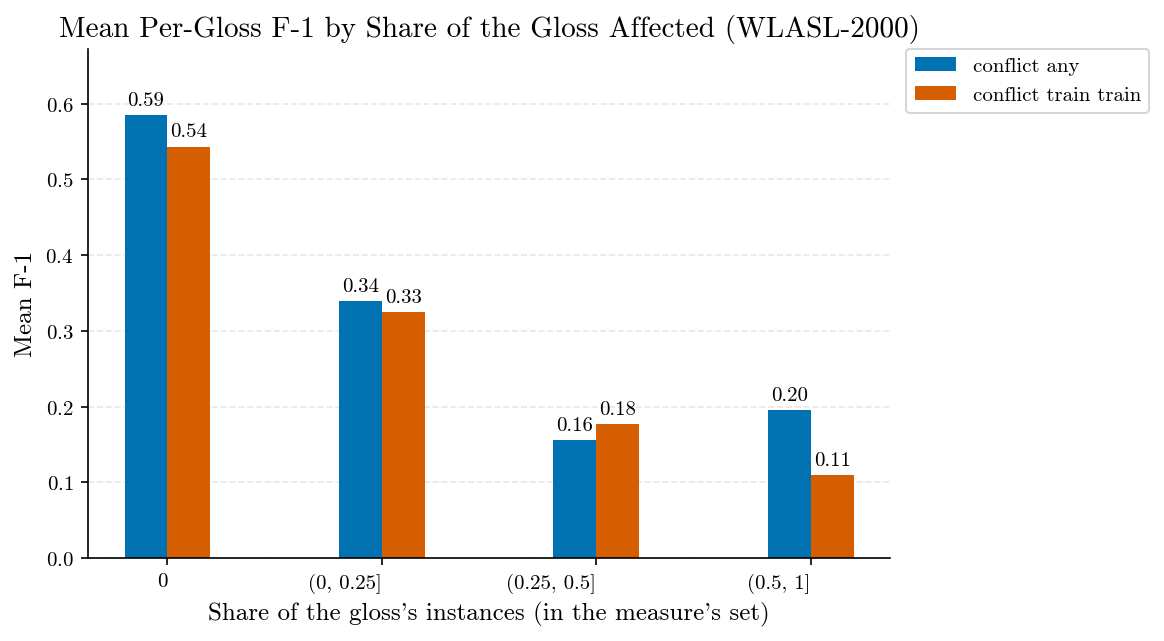

,count,mean
conflict_test_train,,
0.00,1860,0.474
0.25,1,0.000
0.33,5,0.354
0.50,86,0.252
1.00,48,0.000


precision        recall           f1       
                  count   mean  count   mean count   mean
lends_to_test                                            
0                  1837  0.474   1837  0.526  1837  0.476
1                   149  0.162    149  0.285   149  0.200
2                    14  0.060     14  0.071    14  0.064
3+                    0    NaN      0    NaN     0    NaN

In [20]:
share_bins = [-0.001, 0, 0.25, 0.5, 1]
bin_labels = ['0', '(0, 0.25]', '(0.25, 0.5]', '(0.5, 1]']
binned_measures = ['conflict_any', 'conflict_train_train']
binned = {
    m: per_gloss.groupby(pd.cut(per_gloss[m], share_bins, labels=bin_labels), observed=False)['f1'].agg(['count', 'mean'])
    for m in binned_measures
}
display(pd.concat(binned, axis=1).round(3))

fig, ax = plot_grouped_bar_chart(
    bin_labels,
    {m: binned[m]['mean'].fillna(0).to_numpy() for m in binned_measures},
    legend_labels={m: m.replace('_', ' ') for m in binned_measures},
    title='Mean Per-Gloss F-1 by Share of the Gloss Affected (WLASL-2000)',
    xlabel='Share of the gloss\'s instances (in the measure\'s set)',
    ylabel='Mean F-1',
    rotation=0,
)
save_fig(fig, get_asset_path('dup_share_bins_f1', stub, project_name))
plt.show()
display(per_gloss.groupby(per_gloss['conflict_test_train'].round(2))['f1'].agg(['count', 'mean']).round(3))
lent_bins = pd.cut(per_gloss['lends_to_test'], [-1, 0, 1, 2, 100], labels=['0', '1', '2', '3+'])
per_gloss.groupby(lent_bins, observed=False)[['precision', 'recall', 'f1']].agg(['count', 'mean']).round(3)

## Conclusions (as of 2026-11-04, job 4's final model on WLASL-2000)

- **A test clip taught as another gloss is always predicted as that gloss.** All 147 test videos
  whose only training copies carry another gloss are predicted as one of those glosses (top-1 0%,
  but 91.8% have their own gloss in the top 5). A same-gloss copy in train gives 100% (9 videos).
  Test videos with a copy in val under another gloss score 24.4% (41), but 16 of those also have a
  copy in train; the 25 with none are below.
- **Test top-1 is 53.04% as reported, 55.89% without those 147 videos**, and 56.09% without any
  test video that has a copy under another gloss (2699 kept).
- **Every kind of conflict lowers per-gloss F-1, and a leak, if anything, raises it, though not
  significantly.** Against the 1120 glosses with no copy (mean F-1 0.58): any label conflict 0.27
  (849 glosses), train-train 0.27 (663), test-train 0.17 (140), test-val 0.24 (40), test-test 0.19
  (14). The conflict gap holds within every training-signer bin. The 14 glosses with a leaked test
  video score 0.68 (MWU p = 0.35); all 9 test clips leaked from train are predicted correctly
  (3 of 5 leaked from val), which alone lifts recall. The kinds overlap, so these are not separate effects: 20 of the 40 test-val
  glosses also have a test-train conflict, and 28 a train-train conflict.
- **A conflicting copy the model never trained on still costs accuracy, though the cause is
  mixed.** The 25 test clips whose only conflicting copies are in val score 36.0% top-1, against
  55.9% for all clips with no copy and 64.3% for no-copy clips of the same signers and sources
  (weighted to match), so the drop is not a signer or source effect. 10 of their 16 errors are the
  val copy's gloss. For 16 of them the same two glosses
  also share a clip in train, which may explain it; the 9 that don't still score 3 of 9, with
  errors going to a synonym (quick -> fast, stress -> pressure). Viewing those 9 (2026-11-04) found
  no near-duplicate of the predicted gloss in train, so near-synonyms seem to be confused even
  without a shared training clip, but on very few clips.
- **The damage splits between the two glosses of a test-train conflict.** The gloss whose test clip
  was taught as another loses recall (0.16, precision 0.19); the gloss that clip was taught as
  gets a false positive and loses precision (0.15, recall 0.27, over 163 glosses). Precision falls
  from 0.47 with no such clip to 0.16 with one and 0.06 with two.
- **Duplicates track per-gloss F-1 more closely than class size does.** Kendall τ with F-1 is -0.34
  for the share of a gloss's instances in a label conflict and -0.29 for train-train conflicts,
  against +0.19 for training signers and +0.17 for training instances. Mean F-1 falls from 0.59
  with no conflict to 0.34 for up to a quarter of the gloss and 0.16-0.20 above that; the 48 glosses
  whose every test video was taught as another gloss all score 0.
- **So low F-1 on these glosses is mostly label ambiguity, not a weak model**, and per-class results
  on WLASL-2000 partly measure how often a gloss shares a clip.